## Прогнозирование спроса на велопрокат BikeSouth
**Автор:** Куницын Денис

**Дата:** 13 апреля

## Цель и задачи

**Цель:** Построить две нелинейные модели МО (`kNN` и `DecisionTreeRegressor`) для прогнозирования спроса на велопрокат.

**Задачи:**
1. Изучение базового пайплайна с линейной регрессией.
2. Провести исследовательский анализ данных.
3. Провести предобработку данных.
4. Отобрать признаки.
5. Обучить несколько моделей и подобрать гиперпараметры экспериментальным методом.
6. Подготовить финальную модель.
7. Проанализировать важность признаков.
8. Сохранить модель для продакшена.

## Данные

Для анализа, обучения и валидации моделей используется `ds_s14_train_data.csv`, для тестирования — `ds_s14_test_data.csv`.

### Описание датасета `ds_s14_train_data.csv`

- `Temperature` — температура воздуха, °C.
- `Humidity` — относительная влажность воздуха, %.
- `Windspeed` — скорость ветра, м/с.
- `Visibility` — видимость (в десятках метров).
- `Dew Point Temperature` — точка росы, °C.
- `Solar Radiation` — солнечная радиация, MJ/m².
- `Rainfall` — количество осадков, мм.
- `Snowfall` — количество снега, см.
- `Seasons` — время года:
    - `Winter` — зима,
    - `Spring` — весна,
    - `Summer` — лето,
    - `Autumn` — осень.
- `Holiday` — статус дня:
    - `Holiday` — выходной/праздничный день,
    - `No Holiday` — будний день.
- `Functioning Day` — работали ли станции проката:
    - `Yes` — да,
    - `No` — нет (техническое обслуживание).
- `Time_Period_*` — принадлежность записи к одному из временных периодов (`True`/`False`):
    - `Night` — 00:00–05:59,
    - `Morning` — 06:00–09:59,
    - `Daytime` — 10:00–15:59,
    - `Evening` — 16:00–19:59,
    - `Late Evening` — 20:00–23:59.  
    Базовый период — `Daytime`: если во всех остальных колонках периода значение `False`, запись относится к `Daytime`.
- `Rented Bike Count` — **целевая переменная**: количество велосипедов, арендованных за конкретный час. Эта величина отражает почасовой спрос и определяет стабильность логистики компании.


## Структура проекта

1. Подготовка среды и загрузка данных
2. Исследовательский анализ данных
3. Предобработка данных
4. Обучение и сравнение моделей
5. Подготовка финальной модели
6. Финальный отчет и выводы
7. Сохранение модели для продакшена

---

## 1. Подготовка среды и загрузка данных

## 1.1. Подключение требующихся библиотек

In [1]:
requirements_txt = """pandas==2.2.3
numpy==2.0.2
matplotlib==3.9.4
phik==0.12.5
seaborn==0.13.2
scikit-learn==1.5.2
optuna==3.5.0
dotenv==0.9.9
joblib==1.4.2
"""

with open('requirements.txt', 'w', encoding='utf-8') as f:
    f.write(requirements_txt)

!pip -q install -r requirements.txt

You should consider upgrading via the '/Users/dkunicyn/Documents/to-future/bikesouth/venv/bin/python -m pip install --upgrade pip' command.


In [3]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns 
import optuna
import joblib
import dotenv
import os

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import cross_validate, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import make_scorer, root_mean_squared_error, r2_score, mean_absolute_error

/Users/dkunicyn/Documents/to-future/bikesouth/venv/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1.2. Загрузка данных и первичное знакомство

In [4]:
RANDOM_STATE = 42
N_SPLITS = 5

In [5]:
bikesouth = pd.read_csv(os.getenv('TRAIN_DATASET_URL'))

bikesouth.head()

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
0,20.3,35.0,2.4,2000.0,4.3,0.46,0.0,0.0,Autumn,Holiday,Yes,True,False,False,False,1237
1,25.4,55.0,3.2,2000.0,15.6,0.15,0.0,0.0,Autumn,No Holiday,Yes,True,False,False,False,2468
2,-6.9,39.0,1.6,2000.0,-18.5,0.00,0.0,0.0,Winter,No Holiday,Yes,False,True,False,False,186
3,-5.2,37.0,2.2,2000.0,-17.6,0.00,0.0,0.0,Winter,No Holiday,Yes,False,False,False,True,254
4,23.4,34.0,2.1,2000.0,6.6,2.84,0.0,0.0,Autumn,No Holiday,Yes,False,False,False,False,1686


In [6]:
bikesouth.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 16 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Temperature               7008 non-null   float64
 1   Humidity(%)               6758 non-null   float64
 2   Wind speed (m/s)          6798 non-null   float64
 3   Visibility (10m)          6749 non-null   float64
 4   Dew point temperature     7008 non-null   float64
 5   Solar Radiation (MJ/m2)   6798 non-null   float64
 6   Rainfall(mm)              6746 non-null   float64
 7   Snowfall (cm)             6745 non-null   float64
 8   Seasons                   7008 non-null   object 
 9   Holiday                   7008 non-null   object 
 10  Functioning Day           7008 non-null   object 
 11  Time_Period_Evening       7008 non-null   bool   
 12  Time_Period_Late Evening  7008 non-null   bool   
 13  Time_Period_Morning       7008 non-null   bool   
 14  Time_Per

Тренировочный датасет содержит 16 столбцов и 7008 строк.

**Основные выводы после первичного знакомства с данными:**
- Данные имеют подходящие типы данных в зависимости от значения
- Несколько столбцов, отражающих погодные условия (влажность, снегопад и пр.), имеют пропуски. Эти пропуски могут быть связаны как с технической ошибкой (MCAR), так и с несезонностью явления (Снегопад не ожидается летом; MAR).

---

## 2. Исследовательский анализ данных (EDA)

### 2.1. Проверка структуры, пропусков и базовых статистик

In [7]:
TARGET_COL = 'Rented Bike Count'

print('Размер датасета:', bikesouth.shape)
print('Количество дубликатов:', bikesouth.duplicated().sum())

missing_report = (
    bikesouth.isna()
    .mean()
    .sort_values(ascending=False)
    .rename('missing_ratio')
    .to_frame()
)

print('\nДоля пропусков по признакам:')
display(missing_report.head(15))

print('\nОписание целевой переменной:')
display(bikesouth[TARGET_COL].describe())

numeric_cols = bikesouth.select_dtypes(include=['number']).columns.tolist()
categorical_cols = bikesouth.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print('\nЧисловые признаки:', len(numeric_cols))
print('Категориальные/булевы признаки:', len(categorical_cols))

Размер датасета: (7008, 16)
Количество дубликатов: 0

Доля пропусков по признакам:


,missing_ratio
Snowfall (cm),0.037529
Rainfall(mm),0.037386
Visibility (10m),0.036958
Humidity(%),0.035674
Wind speed (m/s),0.029966
Solar Radiation (MJ/m2),0.029966
Temperature,0.000000
Dew point temperature,0.000000
Seasons,0.000000
Holiday,0.000000



Описание целевой переменной:


count    7008.000000
mean      705.606022
std       646.311790
min         0.000000
25%       190.750000
50%       504.500000
75%      1070.000000
max      3556.000000
Name: Rented Bike Count, dtype: float64


Числовые признаки: 9
Категориальные/булевы признаки: 7


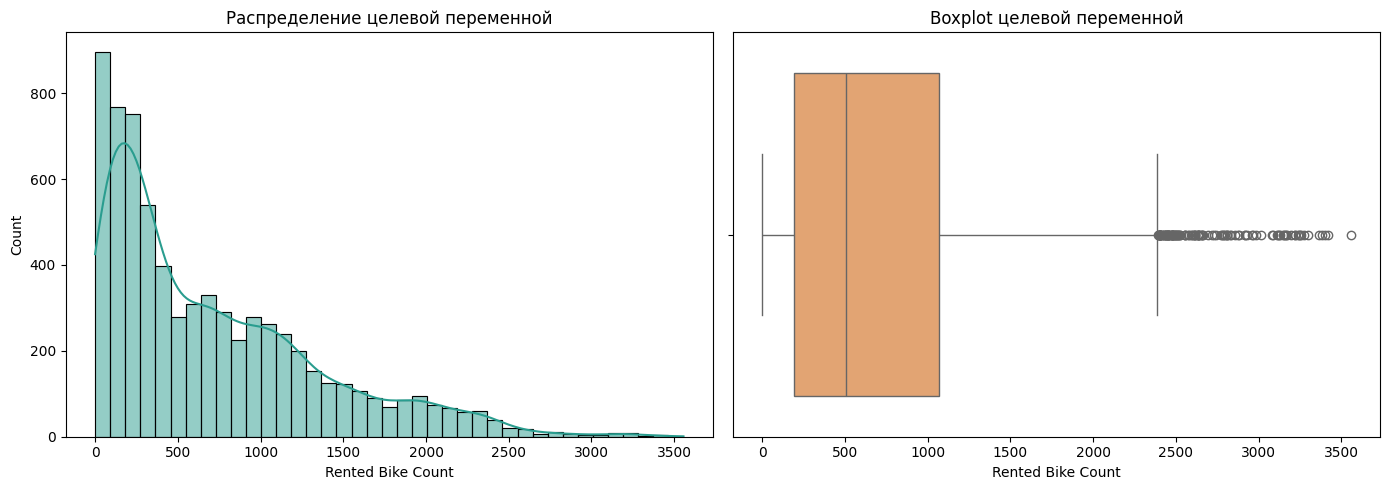

Топ-10 положительных корреляций с целевой переменной:


,corr
Temperature,0.541478
Dew point temperature,0.386701
Solar Radiation (MJ/m2),0.256870
Visibility (10m),0.197705
Wind speed (m/s),0.110949
Rainfall(mm),-0.117923
Snowfall (cm),-0.141062
Humidity(%),-0.189910


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(bikesouth[TARGET_COL], kde=True, ax=axes[0], color='#2a9d8f')
axes[0].set_title('Распределение целевой переменной')
axes[0].set_xlabel(TARGET_COL)

sns.boxplot(x=bikesouth[TARGET_COL], ax=axes[1], color='#f4a261')
axes[1].set_title('Boxplot целевой переменной')
axes[1].set_xlabel(TARGET_COL)

plt.tight_layout()
plt.show()

numeric_for_corr = bikesouth.select_dtypes(include=['number']).copy()
if TARGET_COL in numeric_for_corr.columns:
    corr_with_target = (
        numeric_for_corr.corr(numeric_only=True)[TARGET_COL]
        .drop(TARGET_COL)
        .sort_values(ascending=False)
    )

    print('Топ-10 положительных корреляций с целевой переменной:')
    display(corr_with_target.head(10).to_frame('corr'))

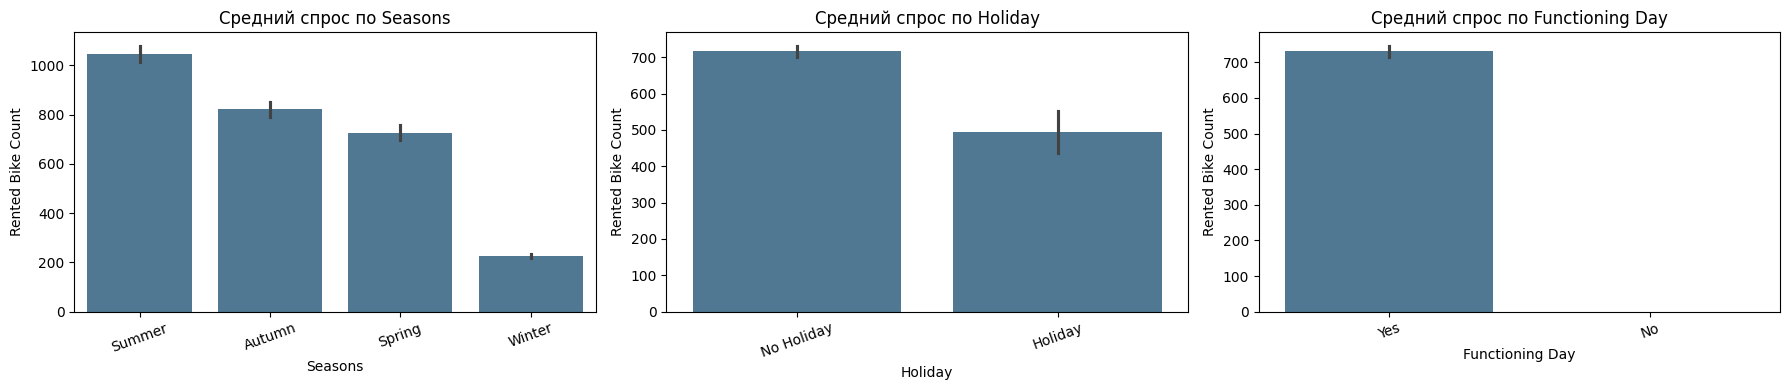

Средний спрос по временным периодам (только где индикатор=True):


,mean_target
Time_Period_Evening,1193.979452
Time_Period_Late Evening,927.049446
Time_Period_Morning,644.337884
Time_Period_Night,288.632059


In [9]:
top_categorical = ['Seasons', 'Holiday', 'Functioning Day']

available_top_categorical = [col for col in top_categorical if col in bikesouth.columns]

if available_top_categorical:
    fig, axes = plt.subplots(1, len(available_top_categorical), figsize=(6 * len(available_top_categorical), 4))
    if len(available_top_categorical) == 1:
        axes = [axes]

    for ax, col in zip(axes, available_top_categorical):
        order = bikesouth.groupby(col)[TARGET_COL].mean().sort_values(ascending=False).index
        sns.barplot(data=bikesouth, x=col, y=TARGET_COL, order=order, ax=ax, color='#457b9d')
        ax.set_title(f'Средний спрос по {col}')
        ax.tick_params(axis='x', rotation=20)

    plt.tight_layout()
    plt.show()

period_cols = [c for c in bikesouth.columns if c.startswith('Time_Period_')]
if period_cols:
    period_demand = bikesouth[period_cols + [TARGET_COL]].copy()
    period_means = period_demand[period_cols].mul(period_demand[TARGET_COL], axis=0).sum() / period_demand[period_cols].sum().replace(0, np.nan)
    period_means = period_means.sort_values(ascending=False)

    print('Средний спрос по временным периодам (только где индикатор=True):')
    display(period_means.to_frame('mean_target'))

**Вывод по итогам EDA:** 

- Целевая переменная имеет скошенное (правостороннее) распределение;
- Доля пропусков в обозначенных столбцах не превышает 4%;
- Наиболее коррелирующие признаки с целевой переменной: `Temperature` (температура), `Dew point temperature` (точка росы), `Solar Radiation` (солнечная радиация).
- Спрос на велопрокат выше всего в летнее время, вечером в непраздничные дни. 

---

## 3. Предобработка данных

### 3.1. Feature engineering и подготовка признаков

In [10]:
class BikeFeatureEngineer(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.log_features = ['Rainfall(mm)', 'Snowfall (cm)', 'Solar Radiation (MJ/m2)']

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X_transformed = X.copy()

        for col in self.log_features:
            if col in X_transformed.columns:
                X_transformed[f'{col}_log1p'] = np.log1p(X_transformed[col].clip(lower=0))

        cols_to_drop = [col for col in self.log_features if col in X_transformed.columns]
        if cols_to_drop:
            X_transformed.drop(columns=cols_to_drop, inplace=True)

        if {'Temperature', 'Humidity(%)'}.issubset(X_transformed.columns):
            X_transformed['Temp_Humidity_Interaction'] = X_transformed['Temperature'] * X_transformed['Humidity(%)']

        if {'Wind speed (m/s)', 'Visibility (10m)'}.issubset(X_transformed.columns):
            X_transformed['Wind_Visibility_Interaction'] = X_transformed['Wind speed (m/s)'] * X_transformed['Visibility (10m)']

        return X_transformed


feature_engineer = BikeFeatureEngineer()
data_fe = feature_engineer.fit_transform(bikesouth)

numeric_features = data_fe.drop(columns=[TARGET_COL]).select_dtypes(include=['number']).columns.tolist()
categorical_features = data_fe.drop(columns=[TARGET_COL]).select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print('Размер матрицы признаков:', data_fe.drop(columns=[TARGET_COL]).shape)
print('Количество числовых признаков:', len(numeric_features))
print('Количество категориальных/булевых признаков:', len(categorical_features))

Размер матрицы признаков: (7008, 17)
Количество числовых признаков: 10
Количество категориальных/булевых признаков: 7


---

### 3.2. Проверка константных и скоррелированных признаков

На этом шаге анализируются признаки после feature engineering:

- константные признаки;
- пары числовых и булевых признаков с высокой корреляцией $|corr| > 0.9$.

Для каждой коррелированной пары предлагается удалить один признак: с большим числом пропусков или, при равенстве, с меньшей связью с целевой переменной.


In [11]:
analysis_features = data_fe.drop(columns=[TARGET_COL]).copy()

# Константные признаки
constant_features = [
    col for col in analysis_features.columns
    if analysis_features[col].nunique(dropna=False) == 1
]

# Корреляции считаем по числовым и булевым признакам
corr_frame = analysis_features.copy()
bool_cols = corr_frame.select_dtypes(include=['bool']).columns.tolist()
if bool_cols:
    corr_frame[bool_cols] = corr_frame[bool_cols].astype(int)

corr_numeric = corr_frame.select_dtypes(include=['number']).copy()

corr_target_frame = corr_numeric.copy()
corr_target_frame[TARGET_COL] = data_fe[TARGET_COL]

target_corr = corr_target_frame.corr(numeric_only=True)[TARGET_COL].drop(TARGET_COL).abs()

corr_matrix = corr_numeric.corr().abs()
upper_triangle = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

corr_threshold = 0.9
high_corr_report = []

for col in upper_triangle.columns:
    related_cols = upper_triangle.index[upper_triangle[col] > corr_threshold].tolist()
    for other_col in related_cols:
        missing_other = analysis_features[other_col].isna().mean()
        missing_col = analysis_features[col].isna().mean()

        if missing_other > missing_col:
            drop_col = other_col
        elif missing_col > missing_other:
            drop_col = col
        else:
            target_other = target_corr.get(other_col, 0)
            target_col = target_corr.get(col, 0)
            drop_col = other_col if target_other < target_col else col

        high_corr_report.append({
            'feature_1': other_col,
            'feature_2': col,
            'corr': corr_matrix.loc[other_col, col],
            'missing_1': missing_other,
            'missing_2': missing_col,
            'target_corr_1': target_corr.get(other_col, 0),
            'target_corr_2': target_corr.get(col, 0),
            'drop_feature': drop_col,
        })

high_corr_df = pd.DataFrame(high_corr_report)

cols_to_drop = sorted(set(constant_features + high_corr_df['drop_feature'].tolist() if not high_corr_df.empty else constant_features))

print('Константные признаки:')
if constant_features:
    display(pd.DataFrame({'constant_feature': constant_features}))
else:
    print('Не найдено.')

print('\nПары признаков с |corr| > 0.9:')
if not high_corr_df.empty:
    display(
        high_corr_df.sort_values('corr', ascending=False)[
            ['feature_1', 'feature_2', 'corr', 'missing_1', 'missing_2', 'target_corr_1', 'target_corr_2', 'drop_feature']
        ]
    )
else:
    print('Не найдено.')

print('\nПризнаки, предложенные к удалению:')
if cols_to_drop:
    display(pd.DataFrame({'feature_to_drop': cols_to_drop}))
else:
    print('Нет признаков для удаления.')

Константные признаки:
Не найдено.

Пары признаков с |corr| > 0.9:


,feature_1,feature_2,corr,missing_1,missing_2,target_corr_1,target_corr_2,drop_feature
1,Dew point temperature,Temp_Humidity_Interaction,0.957124,0.0,0.035674,0.386701,0.366813,Temp_Humidity_Interaction
0,Temperature,Dew point temperature,0.913420,0.0,0.000000,0.541478,0.386701,Dew point temperature



Признаки, предложенные к удалению:


,feature_to_drop
0,Dew point temperature
1,Temp_Humidity_Interaction


`Dew point temperature` встречается в двух случаях мультиколлинеарности. При этом его корреляция с целевой переменной не сильно выше признака `Temp_Humidity_Interaction` и сильно меньше `Temperature`. Поэтому принято решение удалить именно этот признак.

In [12]:
data_fe.drop(columns=['Dew point temperature'], inplace=True, errors='ignore')

numeric_features = data_fe.drop(columns=[TARGET_COL]).select_dtypes(include=['number']).columns.tolist()
categorical_features = data_fe.drop(columns=[TARGET_COL]).select_dtypes(include=['object', 'category', 'bool']).columns.tolist()

print('Размер матрицы признаков:', data_fe.drop(columns=[TARGET_COL]).shape)
print('Количество числовых признаков:', len(numeric_features))
print('Количество категориальных/булевых признаков:', len(categorical_features))

Размер матрицы признаков: (7008, 16)
Количество числовых признаков: 9
Количество категориальных/булевых признаков: 7


In [13]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore')),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ],
    remainder='drop'
)

Препроцессор успешно создан.

---

## 4. Обучение и сравнение моделей



In [14]:
# Отделяем признаки от целевой переменной (feature engineering выполняется внутри пайплайнов)
X = bikesouth.drop(columns=[TARGET_COL])
y = bikesouth[TARGET_COL]

### 4.1. Базовая модель

Заказчик предоставил модель линейной регрессии с требованием улучшить предсказания по сравнению с этой моделью. Поэтому модель заказчика будет использовать в качестве базовой.

In [15]:
# Загрузка базовой модели
baseline_linear_regressor = joblib.load('baseline_linear_regression_pipeline.pkl')

/Users/dkunicyn/Documents/to-future/bikesouth/venv/lib/python3.9/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator SimpleImputer from version 1.6.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/dkunicyn/Documents/to-future/bikesouth/venv/lib/python3.9/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.6.1 when using version 1.5.2. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/Users/dkunicyn/Documents/to-future/bikesouth/venv/lib/python3.9/site-packages/sklearn/base.py:376: InconsistentVersionWarning: Trying to

In [16]:
# Прогноз на тренировочных данных без новых признаков 
baseline_preds = baseline_linear_regressor.predict(bikesouth.drop(columns=[TARGET_COL]))
rmse = root_mean_squared_error(bikesouth[TARGET_COL], baseline_preds)
mae = mean_absolute_error(bikesouth[TARGET_COL], baseline_preds)
r2 = r2_score(bikesouth[TARGET_COL], baseline_preds)
print(f"RMSE: {rmse:.2f}")
print(f"MAE: {mae:.2f}")
print(f"R^2: {r2:.3f}")

RMSE: 412.53
MAE: 309.08
R^2: 0.593


Предсказательная способность базовой модели около 60%, что не является хорошим результатом. Ошибки в 412 велосипедов в час для MSE и 309 для MAE тоже далеки от идеала. 

---

### 4.2. Модель поиска ближайших соседей

Модель поиска ближайших соседей подходит для задачи с условием масштабирования данных, а также отсутствия необходимости экстраполяции данных. В данном проекте погодные условия с малой вероятностью выйдут за пределы исторических, признаки масштабированы на этапе предобработки данных. 

Гиперпараметры будем подбирать с помощью GridSearch, потому что модели поиска ближайщих соседей не требуется время на обучение и, следовательно, процесс не займет много времени. 

In [17]:
param_grid = {
    'model__n_neighbors': [3, 5, 7, 9, 15, 25],
    'model__weights': ['uniform', 'distance'],
    'model__p': [1, 2, 3, 4],
}

In [18]:
# Базовые параметры kNN (без подбора) + кросс-валидация (без hold-out разбиения)
knn_pipeline = Pipeline(
    steps=[
        ('feature_engineer', BikeFeatureEngineer()),
        ('preprocessor', preprocessor),
        ('model', KNeighborsRegressor())
    ]
)

grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=N_SPLITS,
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    verbose=1
)

grid.fit(X, y)

best_knn_model = grid.best_estimator_
best_params = grid.best_params_
print('Лучшие параметры kNN:', best_params)
print('Лучший RMSE на кросс-валидации:', -grid.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Лучшие параметры kNN: {'model__n_neighbors': 7, 'model__p': 1, 'model__weights': 'distance'}
Лучший RMSE на кросс-валидации: 311.2134513722277


In [19]:
cv_scoring = {
    'rmse': 'neg_root_mean_squared_error',
    'mae': 'neg_mean_absolute_error',
    'r2': 'r2'
}

cv_results = cross_validate(
    best_knn_model,
    X,
    y,
    cv=N_SPLITS,
    scoring=cv_scoring,
    n_jobs=-1
)

rmse_folds = -cv_results['test_rmse']
mae_folds = -cv_results['test_mae']
r2_folds = cv_results['test_r2']

cv_report = pd.DataFrame({
    'RMSE': [round(rmse_folds.mean(), 4)],
    'MAE': [round(mae_folds.mean(), 4)],
    'R2': [round(r2_folds.mean(), 4)],
    'RMSE_std': [round(rmse_folds.std(), 4)],
    'MAE_std': [round(mae_folds.std(), 4)],
    'R2_std': [round(r2_folds.std(), 4)],
    'RMSE_cv_%': [rmse_folds.std() / rmse_folds.mean() * 100],
    'MAE_cv_%': [mae_folds.std() / mae_folds.mean() * 100]
})

display(cv_report)

,RMSE,MAE,R2,RMSE_std,MAE_std,R2_std,RMSE_cv_%,MAE_cv_%
0,311.2135,209.0969,0.7676,5.7412,3.7582,0.0118,1.844779,1.797335


---


### 4.3. Модель решающего дерева

Модель решающего дерева позволит выйти за пределы линейных предсказаний модели линейной регрессии и найти нелинейные зависимости. 

Для подбора гиперпараметров модели будем использовать библиотеку Optuna. Для модели решающего дерева, которая имеет большое количество самих гиперпараметров и их значений, необходим оптимизированный подбор, чего GridSearch не в состоянии обеспечить.

In [20]:
def objective(trial):
    params = {
        "max_depth": trial.suggest_int("max_depth", 3, 15),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 50),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 20),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 5, 100),
        "criterion": trial.suggest_categorical("criterion", ["squared_error", "absolute_error"]),
    }

    pipeline = Pipeline([
        ('feature_engineer', BikeFeatureEngineer()),
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(**params, random_state=RANDOM_STATE))
    ])

    scores = cross_val_score(
        pipeline,
        X,
        y,
        cv=N_SPLITS,
        scoring=make_scorer(root_mean_squared_error),
        n_jobs=-1
    )

    mean_score = scores.mean()

    # Сообщаем результат Optuna
    trial.report(mean_score, step=0)

    # Если результат плохой — прерываем итерацию
    if trial.should_prune():
        raise optuna.TrialPruned()
    
    return mean_score

In [21]:
sampler = optuna.samplers.TPESampler(seed=RANDOM_STATE)
study = optuna.create_study(direction="minimize", sampler=sampler) 
study.optimize(objective, n_trials=30, show_progress_bar=True)

# Лучшие гиперпараметры и качество
best_decision_tree_params = study.best_params
print("Лучшие гиперпараметры:", best_decision_tree_params)
best_decision_tree_value = study.best_value
print("Лучшее значение RMSE:", round(best_decision_tree_value, 4))

[I 2026-04-14 07:13:29,307] A new study created in memory with name: no-name-ec904b07-c12c-42f6-a7b0-1a77d7035f08
Best trial: 0. Best value: 336.007:   3%|▎         | 1/30 [00:00<00:02,  9.70it/s]

[I 2026-04-14 07:13:29,410] Trial 0 finished with value: 336.00671140070324 and parameters: {'max_depth': 7, 'min_samples_split': 48, 'min_samples_leaf': 15, 'max_leaf_nodes': 62, 'criterion': 'squared_error'}. Best is trial 0 with value: 336.00671140070324.


Best trial: 0. Best value: 336.007:   7%|▋         | 2/30 [00:01<00:17,  1.59it/s]

[I 2026-04-14 07:13:30,410] Trial 1 finished with value: 475.2427006701966 and parameters: {'max_depth': 3, 'min_samples_split': 44, 'min_samples_leaf': 13, 'max_leaf_nodes': 72, 'criterion': 'absolute_error'}. Best is trial 0 with value: 336.00671140070324.


Best trial: 0. Best value: 336.007:  10%|█         | 3/30 [00:02<00:25,  1.08it/s]

[I 2026-04-14 07:13:31,696] Trial 2 finished with value: 352.97568625399344 and parameters: {'max_depth': 13, 'min_samples_split': 12, 'min_samples_leaf': 4, 'max_leaf_nodes': 22, 'criterion': 'absolute_error'}. Best is trial 0 with value: 336.00671140070324.


... (16 outputs left out)

Best trial: 12. Best value: 322.296:  87%|████████▋ | 26/30 [00:08<00:00,  9.11it/s]

[I 2026-04-14 07:13:37,966] Trial 24 finished with value: 322.84315838921214 and parameters: {'max_depth': 11, 'min_samples_split': 30, 'min_samples_leaf': 12, 'max_leaf_nodes': 89, 'criterion': 'squared_error'}. Best is trial 12 with value: 322.29551375196667.
[I 2026-04-14 07:13:38,045] Trial 25 finished with value: 323.1497047676382 and parameters: {'max_depth': 14, 'min_samples_split': 40, 'min_samples_leaf': 19, 'max_leaf_nodes': 99, 'criterion': 'squared_error'}. Best is trial 12 with value: 322.29551375196667.
[I 2026-04-14 07:13:38,157] Trial 26 pruned. 


Best trial: 12. Best value: 322.296: 100%|██████████| 30/30 [00:09<00:00,  3.29it/s]

[I 2026-04-14 07:13:38,249] Trial 27 pruned. 
[I 2026-04-14 07:13:38,327] Trial 28 pruned. 
[I 2026-04-14 07:13:38,416] Trial 29 pruned. 
Лучшие гиперпараметры: {'max_depth': 12, 'min_samples_split': 2, 'min_samples_leaf': 20, 'max_leaf_nodes': 100, 'criterion': 'squared_error'}
Лучшее значение RMSE: 322.2955


In [22]:
decision_tree_pipeline = Pipeline(
    steps=[
        ('feature_engineer', BikeFeatureEngineer()),
        ('preprocessor', preprocessor),
        ('regressor', DecisionTreeRegressor(random_state=RANDOM_STATE, **best_decision_tree_params))
    ]
)

tree_cv_results = cross_validate(
    decision_tree_pipeline,
    X,
    y,
    cv=N_SPLITS,
    scoring={
        'rmse': 'neg_root_mean_squared_error',
        'mae': 'neg_mean_absolute_error',
        'r2': 'r2'
    },
    n_jobs=-1
)

# Отклонения метрик по фолдам для оценки стабильности модели
rmse_folds = -tree_cv_results['test_rmse']
mae_folds = -tree_cv_results['test_mae']
r2_folds = tree_cv_results['test_r2']

tree_cv_report = pd.DataFrame({
    'RMSE': [rmse_folds.mean()],
    'MAE': [mae_folds.mean()],
    'R2': [r2_folds.mean()],
    'RMSE_std': [rmse_folds.std()],
    'MAE_std': [mae_folds.std()],
    'R2_std': [r2_folds.std()],
    'RMSE_cv_%': [rmse_folds.std() / rmse_folds.mean() * 100],
    'MAE_cv_%': [mae_folds.std() / mae_folds.mean() * 100]
}).round(4) 

display(tree_cv_report)


,RMSE,MAE,R2,RMSE_std,MAE_std,R2_std,RMSE_cv_%,MAE_cv_%
0,322.2955,216.0004,0.7511,8.3172,6.7241,0.0073,2.5806,3.113


---

### 4.4. Сравнение моделей

In [24]:
# Сводная таблица по моделям (без повторной CV для базовой модели)
baseline_summary = pd.DataFrame({
    'RMSE': [rmse],
    'MAE': [mae],
    'R2': [r2],
    'RMSE_std': [float('nan')],
    'MAE_std': [float('nan')],
    'R2_std': [float('nan')]
}, index=['Базовая модель'])

knn_summary = cv_report.copy()
if 'RMSE_std' not in knn_summary.columns:
    knn_summary['RMSE_std'] = (-cv_results['test_rmse']).std()
if 'MAE_std' not in knn_summary.columns:
    knn_summary['MAE_std'] = (-cv_results['test_mae']).std()
if 'R2_std' not in knn_summary.columns:
    knn_summary['R2_std'] = cv_results['test_r2'].std()
knn_summary = knn_summary[['RMSE', 'MAE', 'R2', 'RMSE_std', 'MAE_std', 'R2_std']]
knn_summary.index = ['kNN']

tree_summary = tree_cv_report.copy()
if 'RMSE_std' not in tree_summary.columns:
    tree_summary['RMSE_std'] = (-tree_cv_results['test_rmse']).std()
if 'MAE_std' not in tree_summary.columns:
    tree_summary['MAE_std'] = (-tree_cv_results['test_mae']).std()
if 'R2_std' not in tree_summary.columns:
    tree_summary['R2_std'] = tree_cv_results['test_r2'].std()
tree_summary = tree_summary[['RMSE', 'MAE', 'R2', 'RMSE_std', 'MAE_std', 'R2_std']]
tree_summary.index = ['Решающее дерево']

models_comparison = pd.concat([
    baseline_summary,
    knn_summary,
    tree_summary
]).round(4)

models_comparison.sort_values('RMSE', inplace=True, ascending=True)

models_comparison

,RMSE,MAE,R2,RMSE_std,MAE_std,R2_std
kNN,311.2135,209.0969,0.7676,5.7412,3.7582,0.0118
Решающее дерево,322.2955,216.0004,0.7511,8.3172,6.7241,0.0073
Базовая модель,412.5264,309.0784,0.5925,NaN,NaN,NaN


После подбора гиперпараметров лучшие результаты на кросс-валидации показала модель поиска ближайших соседей. Ее метрики ошибок значительно меньше модели решающего дерева, а предсказательная способность выше. Помимо метрик, модель kNN стабильнее - стандартное отклонение по сплитам кросс-валидации меньше.

Финальной моделью для тестирования выступит kNN.

---

## 5. Подготовка финальной модели

### 5.1. Проверка модели на тестовых данных 

In [25]:
bikesouth_test = pd.read_csv(os.getenv('TEST_DATASET_URL'))

bikesouth_test.head()

,Temperature,Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature,Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day,Time_Period_Evening,Time_Period_Late Evening,Time_Period_Morning,Time_Period_Night,Rented Bike Count
0,6.7,48.0,0.8,817.0,-3.5,0.39,0.0,0.0,Winter,No Holiday,Yes,False,False,False,False,402
1,-5.3,90.0,1.1,311.0,-6.6,0.00,0.0,2.2,Winter,No Holiday,Yes,False,False,True,False,178
2,2.9,66.0,1.2,173.0,-2.8,0.00,0.0,0.0,Winter,No Holiday,Yes,False,True,False,False,219
3,23.1,63.0,2.6,949.0,15.6,1.68,0.0,0.0,Spring,No Holiday,Yes,False,False,False,False,949
4,23.3,43.0,1.2,1257.0,10.0,1.91,0.0,0.0,Summer,No Holiday,Yes,False,False,True,False,1005


In [26]:
X_test = bikesouth_test.drop(columns=[TARGET_COL], errors='ignore')
y_test = bikesouth_test[TARGET_COL]

best_knn_model.fit(X, y)
knn_test_preds = best_knn_model.predict(X_test)
knn_test_mse = root_mean_squared_error(y_test, knn_test_preds)
knn_test_mae = mean_absolute_error(y_test, knn_test_preds)
knn_test_r2 = r2_score(y_test, knn_test_preds)

knn_cv_rmse = float(cv_report.loc[0, 'RMSE'])
knn_cv_mae = float(cv_report.loc[0, 'MAE'])
knn_cv_r2 = float(cv_report.loc[0, 'R2'])

print(f"kNN (CV) - RMSE: {knn_cv_rmse:.4f}, MAE: {knn_cv_mae:.4f}, R2: {knn_cv_r2:.4f}")
print(f"kNN - RMSE: {knn_test_mse:.4f}, MAE: {knn_test_mae:.4f}, R2: {knn_test_r2:.4f}")

kNN (CV) - RMSE: 311.2135, MAE: 209.0969, R2: 0.7676
kNN - RMSE: 315.5790, MAE: 210.7600, R2: 0.7566


Модель незначительно потеряла в качестве на тесте, что является нормой. Модель не показывает признаков переобучения. 

---

### 5.2. Оценка важности признаков

Модель поиска ближайших соседей не позволяет оценить важность признаков, потому что просто ищет подходящих соседей. 

Это один из недостатков модели, который, тем не менее, некритичен для поставленой задачи. 

Задача заключалась в улучшении предсказания спроса на велопрокат, а интерпретация признаков вторична. Однако, исходя из специфики задачи, можно с уверенностью сказать, что на спрос прежде всего влияют сезонность и погодные условия. Это также следует из корреляционного анализа признаков.

---

## 6. Финальный отчет и выводы

#### Краткие выводы по проекту:

- Построена и протестирована модель kNN, которая существенно превосходит базовую линейную регрессию по всем метрикам (RMSE, MAE, R2).
- Весь feature engineering реализован в виде sklearn-трансформера и встроен в Pipeline, что обеспечивает корректную обработку новых данных и удобную интеграцию в продакшен.
- Ключевые факторы спроса — сезонность и погодные условия, что подтверждено анализом данных и результатами моделей.
- Модель показала стабильные результаты на тестовой выборке, признаки переобучения отсутствуют.

Проект полностью реализует задачу прогнозирования спроса на велопрокат и готов к внедрению.

#### Рекомендации:

Для дальнейшего повышения качества можно рассмотреть ансамблирование моделей и расширение feature engineering. 

---

## 7. Сохранение модели для продакшена

In [27]:
# 1) Дообучаем финальный kNN-пайплайн на всех train-данных и сохраняем
best_knn_model.fit(X, y)
model_path = "knn_final_pipeline.pkl"
joblib.dump(best_knn_model, model_path)

# 2) Считаем и сохраняем метрики на тесте
test_metrics = pd.DataFrame([{
    "RMSE": root_mean_squared_error(y_test, best_knn_model.predict(X_test)),
    "MAE": mean_absolute_error(y_test, best_knn_model.predict(X_test)),
    "R2": r2_score(y_test, best_knn_model.predict(X_test)),
}])

metrics_path = "knn_test_metrics.csv"
test_metrics.to_csv(metrics_path, index=False)

print(f"Модель сохранена: {model_path}")
print(f"Метрики сохранены: {metrics_path}")
display(test_metrics)

Модель сохранена: knn_final_pipeline.pkl
Метрики сохранены: knn_test_metrics.csv


,RMSE,MAE,R2
0,315.579008,210.760013,0.756631


In [28]:
# Загружаем сохраненную модель и проверяем, что она делает предсказания
loaded_model = joblib.load(model_path)

# Признаки для инференса (без целевой переменной)
X_test_infer = bikesouth_test.drop(columns=[TARGET_COL], errors='ignore')

# Проверка предсказаний
loaded_preds = loaded_model.predict(X_test_infer)

# Быстрая проверка качества на тесте
loaded_rmse = root_mean_squared_error(y_test, loaded_preds)
loaded_mae = mean_absolute_error(y_test, loaded_preds)
loaded_r2 = r2_score(y_test, loaded_preds)

print(f"RMSE: {loaded_rmse:.4f}")
print(f"MAE: {loaded_mae:.4f}")
print(f"R2: {loaded_r2:.4f}")

RMSE: 315.5790
MAE: 210.7600
R2: 0.7566


Модель успешно сохранена для использования в продакшене. 

---